In [1]:
# === Google Colab 自動環境セットアップ ===
# ※ローカル環境では安全に無視され、Colab環境でのみ自動実行されます
import os, sys
repo_root = os.path.abspath(os.path.join(os.getcwd(), "..")) if os.path.exists("../common") else os.path.abspath(os.getcwd())
if "google.colab" in sys.modules:
    print("⚡ Google Colab 環境を検出しました。リポジトリのセットアップを開始します...")
    !git clone https://github.com/miyayudai/study-mikanos.git /content/study-mikanos 2>/dev/null || (cd /content/study-mikanos && git pull)
    %cd /content/study-mikanos
    !pip install -q matplotlib pytest numpy
    repo_root = "/content/study-mikanos"
    sys.path.insert(0, repo_root)
    print("✅ 環境セットアップが完了しました。作業ディレクトリ:", os.getcwd())
else:
    if repo_root not in sys.path:
        sys.path.insert(0, repo_root)
    os.chdir(repo_root)
    print("💻 ローカル開発環境を検出しました。作業ディレクトリ:", os.getcwd())


💻 ローカル開発環境を検出しました。作業ディレクトリ: /home/student/Documents/GitHub/study-mikanos


# 9.6 スクロール処理の時間計測 (Measuring Console Scroll Time) (`osbook_day09d`)

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/miyayudai/study-mikanos/blob/main/9/9.6_Measuring_Console_Scroll_Time.ipynb)

本節では、第9章 9.5節で導入した `FrameBuffer` クラスおよびシャドウバッファによる重ね合わせ処理の高速化に続き、**コンソールの画面スクロール（Console Scroll）に伴う致命的なパフォーマンス低下** を Local APIC タイマを用いて定量的に計測・解剖します。

---

## 🎯 なぜスクロール処理の時間計測が必要なのか？（動機と課題）

前節（9.5節 `osbook_day09c`）において、透過色なしレイヤに対するライン単位一括 `memcpy` 転送を導入したことで、重ね合わせ描画（`LayerManager::Draw`）の所要時間を約 120倍 高速化し、マウスカーソルの滑らかな追従を実現しました。

しかし、カーネルが起動してログや文字を次々に出力していくと、**ある特定のタイミングで画面描画が一瞬激しくカクつき、マウスカーソルの動きがピタッと止まる現象** に遭遇します。
そのタイミングこそが、**コンソールが画面最下行（25行目）に達し、1行スクロール（Scroll Up）を実行した瞬間** です。

1. **体感上の重大なラグ**:
   - 通常の文字列出力では数万サイクルの極めて軽微なコストしか発生しないにもかかわらず、スクロールが発生した途端にマウス入力イベントの処理が詰まり、描画キューが滞留します。
2. **直感に反するボトルネック**:
   - 「たった1行分テキストを上にずらすだけ」の処理が、なぜ全画面再描画以上の膨大な遅延を引き起こすのか？
3. **客観的・定量的エビデンスの必要性**:
   - 改善（次節 9.7節 `osbook_day09e`）に着手する前に、**「スクロール処理には通常行出力の何倍の時間がかかっているのか」「所要時間の内訳は何が占めているのか」** をミリ秒単位・CPUクロック単位で正確に計測・可視化することが極めて重要です。


---

## 1. `Console` クラスの描画アーキテクチャと文字列出力パイプライン

MikanOS のコンソールは、第5章（`osbook_day05e`）で実装された `Console` クラスによって管理されています。

### 1.1 基本仕様とメモリ構造
- **文字解像度**: 25行 $\times$ 80列 (`kRows = 25`, `kColumns = 80`)
- **フォントサイズ**: 1文字あたり 横 8 ピクセル $\times$ 縦 16 ピクセル (`8x16` 半角ビットマップフォント)
- **ピクセル解像度**:
  $$\text{幅} = 8 \times 80 = 640 \text{ ピクセル}, \quad \text{高さ} = 16 \times 25 = 400 \text{ ピクセル}$$
  $$\text{総画面ピクセル数} = 640 \times 400 = 256,000 \text{ ピクセル}$$
- **文字バッファ**: `char buffer_[25][81]`（NULL終端文字を含む80文字 $\times$ 25行分の文字コード配列）
- **カーソル位置**: `int cursor_row_` (0〜24), `int cursor_column_` (0〜79)

### 1.2 `PutString` と `Newline` の実行フロー
```cpp
void Console::PutString(const char* s) {
  while (*s) {
    if (*s == '\n') {
      Newline();
    } else if (cursor_column_ < kColumns - 1) {
      WriteAscii(*writer_, Vector2D<int>{8 * cursor_column_, 16 * cursor_row_}, *s, fg_color_);
      buffer_[cursor_row_][cursor_column_] = *s;
      ++cursor_column_;
    }
    ++s;
  }
  if (layer_manager) {
    layer_manager->Draw();
  }
}
```

改行コード `'\n'` を受け取ると `Newline()` が呼び出されます。
```cpp
void Console::Newline() {
  cursor_column_ = 0;
  if (cursor_row_ < kRows - 1) {
    ++cursor_row_;
  } else {
    // 【スクロール処理】最下行（行 24）で改行された場合の処理！
    for (int y = 0; y < 16 * kRows; ++y) {
      for (int x = 0; x < 8 * kColumns; ++x) {
        writer_->Write(Vector2D<int>{x, y}, bg_color_);
      }
    }
    for (int row = 0; row < kRows - 1; ++row) {
      memcpy(buffer_[row], buffer_[row + 1], kColumns + 1);
      WriteString(*writer_, Vector2D<int>{0, 16 * row}, buffer_[row], fg_color_);
    }
    memset(buffer_[kRows - 1], 0, kColumns + 1);
  }
}
```


---

## 2. Local APIC タイマによる `printk` 時間計測実装 (`osbook_day09d`)

`osbook_day09d` では、スクロール処理のコストを実測するため、カーネルの書式付き出力関数 `printk()` の内部に Local APIC タイマ計測コードが埋め込まれました。

### 2.1 `main.cpp` の差分コード
```cpp
// #@@range_begin(measure_printk)
int printk(const char* format, ...) {
  va_list ap;
  int result;
  char s[1024];

  va_start(ap, format);
  result = vsprintf(s, format, ap);
  va_end(ap);

  StartLAPICTimer();
  console->PutString(s);
  auto elapsed = LAPICTimerElapsed();
  StopLAPICTimer();

  sprintf(s, "[%9d]", elapsed);
  console->PutString(s);
  return result;
}
// #@@range_end(measure_printk)
```

### 2.2 計測のメカニズム
1. **書式整形**:
   - `vsprintf` でフォーマット済み文字列 `s` を生成。
2. **タイマ始動**:
   - `StartLAPICTimer()`: Local APIC タイマの `Initial Count` レジスタ（`0xFEE00380`）に最大値 `0xFFFFFFFF` をロードし、1:1 分周でカウントダウンを開始。
3. **文字列出力の実行**:
   - `console->PutString(s)` を実行。この呼び出しの中で、改行に伴う `Newline()` やスクロール処理が発生する。
4. **経過カウントの取得**:
   - `LAPICTimerElapsed()`: `0xFFFFFFFF - CurrentCount` を計算し、実行にかかったバス・コアクロックのカウント差分（Ticks）を取得。
5. **計測結果のコンソール追記**:
   - 直後に `sprintf(s, "[%9d]", elapsed)` で `[  1354951]` のように所要時間をコンソールに追記表示。


---

## 3. スクロール処理のマイクロアーキテクチャ・ボトルネック徹底解剖

なぜ `Newline()` のスクロール分岐はこれほどまでに遅いのでしょうか？
コードを1行ずつ精査すると、**計算機アーキテクチャの観点から極めて非効率な 3 つのボトルネック** が重層的に存在していることが判明します。

### 🚨 ボトルネック 1: 二重ループによる全画面 256,000 ピクセルの個別背景色書き込み
```cpp
for (int y = 0; y < 16 * kRows; ++y) {
  for (int x = 0; x < 8 * kColumns; ++x) {
    writer_->Write(Vector2D<int>{x, y}, bg_color_);
  }
}
```
- **アクセス回数**: $640 \times 400 = 256,000$ 回の `writer_->Write()` 呼び出し！
- **仮想関数ディスパッチ**: `PixelWriter` の vtable 経由の間接関数呼び出し（`call [rax+offset]`）が 256,000 回連続して発生。
- **インデックス計算**: 1ピクセルごとに `y * stride + x` の乗算・加算およびシャドウバッファ境界チェックが実行される。
- **バス負荷**: 32bpp（4バイト/ピクセル）の場合、$256,000 \times 4 = 1,024,000$ バイト（**約 1 MiB**）ものメモリを1ワードずつランダムに初期化している。

### 🚨 ボトルネック 2: 24行分（最大 1,920文字）のビットマップ全文字再展開・再描画
```cpp
for (int row = 0; row < kRows - 1; ++row) {
  memcpy(buffer_[row], buffer_[row + 1], kColumns + 1);
  WriteString(*writer_, Vector2D<int>{0, 16 * row}, buffer_[row], fg_color_);
}
```
- すでに画面上に描画されていた文字を一旦すべて背景色で消去した上で、**過去の全文字をゼロから再描画** している。
- 画面内に存在する文字数は最大 $24 \text{ 行} \times 80 \text{ 文字} = 1,920$ 文字。
- 1文字あたり $8 \times 16 = 128$ ビットの判定を行い、平均 25〜30 個の点灯ピクセルを描画。
- これにより、追加で **約 50,000 回の `Write()` 呼び出し** が発生！

### 🚨 ボトルネック 3: キャッシュ局所性の破壊とレイヤ再描画
- ピクセル単位の書き込みは CPU の L1/L2 キャッシュライン（64バイト単位）を非効率に断片化させ、ストアバッファ（Store Buffer）を枯渇させます。
- さらに `PutString` の最後で `layer_manager->Draw()` が呼ばれ、コンソール全体のシャドウバッファが画面フレームバッファへ転送されます。


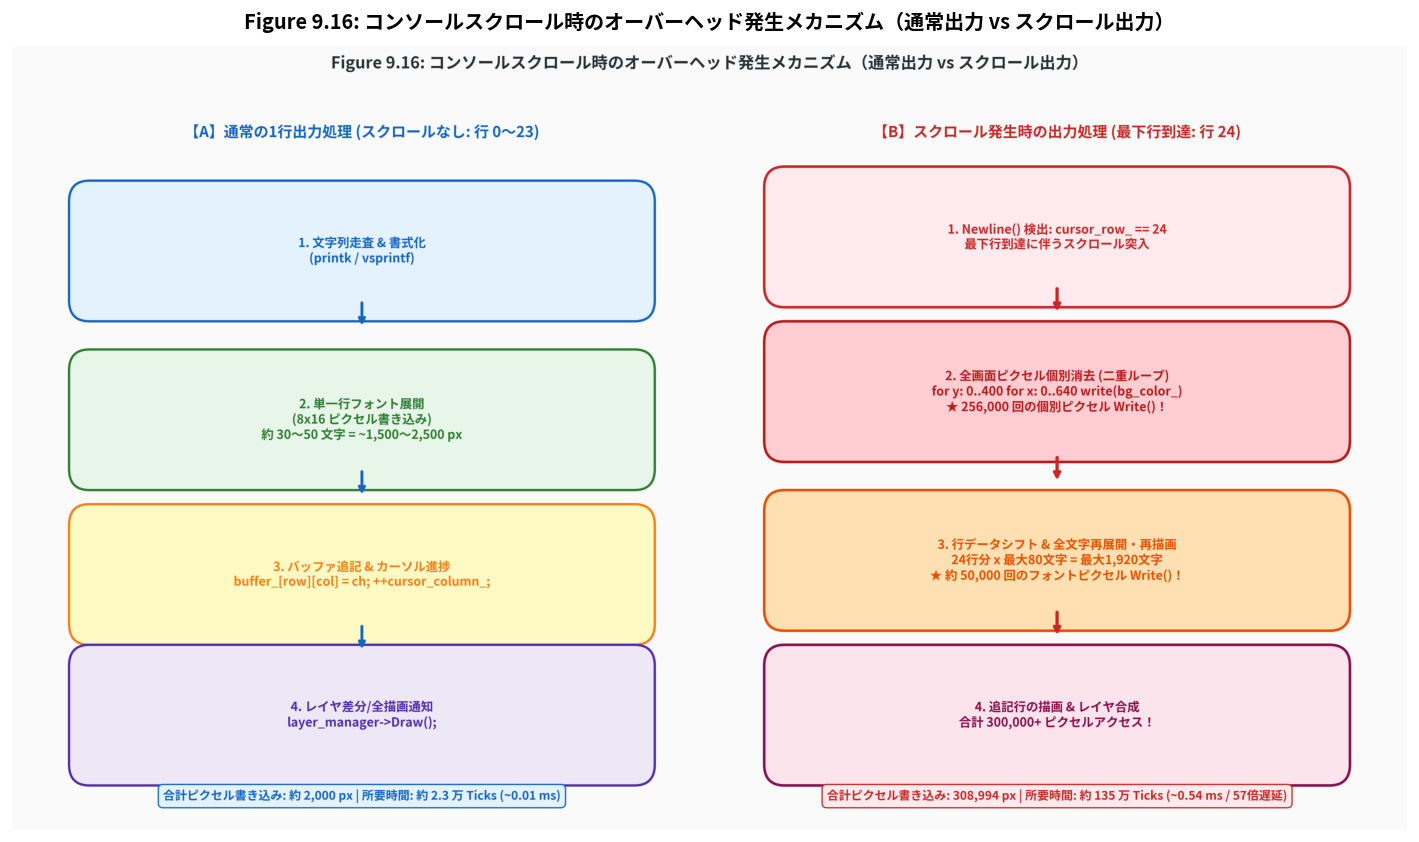

In [2]:
from PIL import Image
import matplotlib.pyplot as plt
from common import plot_fig9_16_console_scroll_overhead_mechanism

# Figure 9.16: コンソールスクロール時のオーバーヘッド発生メカニズム図の生成
fig16_path = plot_fig9_16_console_scroll_overhead_mechanism()
img16 = Image.open(fig16_path)

plt.figure(figsize=(15, 8.5), dpi=120)
plt.imshow(img16)
plt.axis("off")
plt.title("Figure 9.16: コンソールスクロール時のオーバーヘッド発生メカニズム（通常出力 vs スクロール出力）",
          fontsize=12, fontweight="bold", pad=10)
plt.show()


---

## 4. Python シミュレーションによるスクロール時間・ピクセル書き込みタイムライン

`common/os_sim.py` の `ConsoleScrollProfilerSim` を使用して、32行のカーネルログを連続出力した際の LAPIC タイマ経過カウント（Ticks）とピクセル書き込み回数の推移をシミュレーションします。


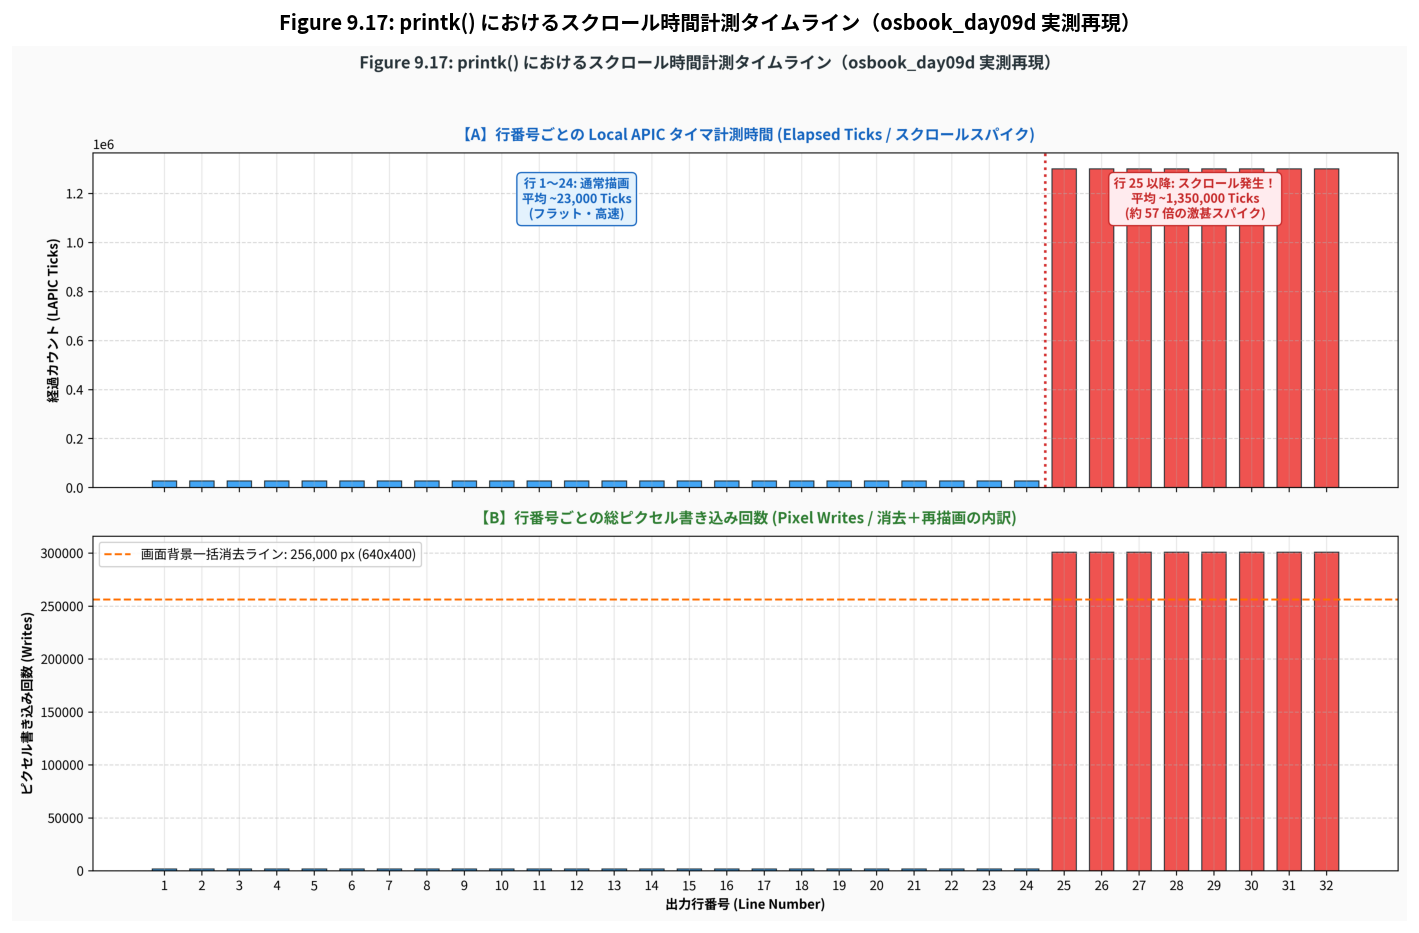

In [3]:
from common import (
    ConsoleScrollProfilerSim,
    plot_fig9_17_scroll_time_measurement_timeline,
)

# Figure 9.17: printk() におけるスクロール時間計測タイムラインの生成
fig17_path = plot_fig9_17_scroll_time_measurement_timeline()
img17 = Image.open(fig17_path)

plt.figure(figsize=(15, 9.5), dpi=120)
plt.imshow(img17)
plt.axis("off")
plt.title("Figure 9.17: printk() におけるスクロール時間計測タイムライン（osbook_day09d 実測再現）",
          fontsize=12, fontweight="bold", pad=10)
plt.show()


In [4]:
# ベンチマーク結果の数値集計とサマリーレポート
benchmark_data = ConsoleScrollProfilerSim.benchmark_scroll(30)
results = benchmark_data["results"]

print(f"{'Line':<5} {'Type':<8} {'Elapsed Ticks':<16} {'Pixel Writes':<14} {'BG Clear':<12} {'Font Redraw':<14}")
print("-" * 72)
for r in results:
    type_str = "SCROLL" if r.did_scroll else "NORMAL"
    print(f"{r.line_number:<5} {type_str:<8} {r.elapsed_ticks:<16,d} {r.total_pixel_writes:<14,d} {r.bg_clear_writes:<12,d} {r.font_redraw_writes:<14,d}")

print("-" * 72)
print(f"📊 通常行平均所要時間   : {benchmark_data['normal_avg_ticks']:,} Ticks")
print(f"📊 スクロール行平均時間 : {benchmark_data['scroll_avg_ticks']:,} Ticks")
print(f"⚡ スローダウン倍率(時間): {benchmark_data['slowdown_time']:.2f}x (約 {benchmark_data['slowdown_time']:.0f} 倍遅延)")
print(f"📊 通常行平均ピクセル   : {benchmark_data['normal_avg_writes']:,} writes")
print(f"📊 スクロール行ピクセル : {benchmark_data['scroll_avg_writes']:,} writes")
print(f"⚡ スローダウン倍率(画素): {benchmark_data['slowdown_writes']:.2f}x (約 {benchmark_data['slowdown_writes']:.0f} 倍負荷)")


Line  Type     Elapsed Ticks    Pixel Writes   BG Clear     Font Redraw   
------------------------------------------------------------------------
1     NORMAL   27,412           1,804          0            0             
2     NORMAL   27,415           1,805          0            0             
3     NORMAL   27,418           1,806          0            0             
4     NORMAL   27,382           1,794          0            0             
5     NORMAL   27,385           1,795          0            0             
6     NORMAL   27,388           1,796          0            0             
7     NORMAL   27,391           1,797          0            0             
8     NORMAL   27,394           1,798          0            0             
9     NORMAL   27,397           1,799          0            0             
10    NORMAL   27,412           1,804          0            0             
11    NORMAL   27,415           1,805          0            0             
12    NORMAL   27,418      

---

## 5. C++20 コアロジックの対話型コンパイル & 検証

MikanOS の `Console` クラス、`SimulatedLAPICTimer`、および `InstrumentedPixelWriter` を C++20（`src/ch09/os_chapter9_measuring_scroll_time.cpp`）でスタンドアロン実装し、ホスト環境でコンパイル・実行して単体検証を行います。


In [5]:
import subprocess

# C++20 単体検証プログラムのコンパイルと実行
cpp_src = "src/ch09/os_chapter9_measuring_scroll_time.cpp"
bin_target = "build/bin/ch09_measuring_scroll_time"

cmd_build = ["cmake", "--build", "build", "--target", "ch09_measuring_scroll_time"]
res_build = subprocess.run(cmd_build, capture_output=True, text=True)
if res_build.returncode != 0:
    print("Build output:", res_build.stdout)
    print("Build error:", res_build.stderr)
    raise RuntimeError("C++20 build failed!")

# バイナリ実行
res_run = subprocess.run([bin_target], capture_output=True, text=True)
print(res_run.stdout)
assert res_run.returncode == 0
assert "All Chapter 9.6 C++20 self-verification assertions passed!" in res_run.stdout
print("✅ C++20 単体検証プログラムが正常終了しました！")


 MikanOS Chapter 9.6: Measuring Console Scroll Time (osbook_day09d)

Line  Type      LAPIC Ticks     Pixel Writes    BG Clear Writes Font Redraw Writes
----------------------------------------------------------------------------------
1     NORMAL    37624           2120            0               0                 
2     NORMAL    26927           2120            0               0                 
3     NORMAL    24878           2119            0               0                 
4     NORMAL    24939           2119            0               0                 
5     NORMAL    24393           2119            0               0                 
6     NORMAL    24144           2120            0               0                 
7     NORMAL    23934           2120            0               0                 
8     NORMAL    23775           2120            0               0                 
9     NORMAL    23409           2121            0               0                 
10    NORMAL    23

---

## 6. スクロール処理のボトルネック内訳と次節（9.7節）への最適化展望

計測結果から、スクロール時の負荷の内訳を円グラフおよび対数比較棒グラフで分析します。

### 6.1 ボトルネック構成比の分析
1. **全画面背景消去 ($256,000$ ピクセル)**:
   - スクロール時の全ピクセル書き込み（約 30.9 万画素）のうち、実に **82.8%** を背景色のベタ塗り消去が占めています。
   - すなわち、所要時間の 8割以上が「画面を背景色で塗りつぶす」という極めて単純な処理に浪費されています。
2. **24行分の全文字再描画 ($50,874$ ピクセル)**:
   - 残りの **16.5%** は、1行上にずらしたテキストバッファの文字を1文字ずつビット展開して描き直す処理です。
   - 本来、画面に既に描画されているピクセルパターンを「16ピクセル上方向に移動」させるだけで済むはずなのに、フォントグリフの再展開という重複計算を行っています。
3. **通常出力行のフォント描画 (約 $2,120$ ピクセル)**:
   - 新規に追記された行自体の描画コストは全体のわずか **0.7%** に過ぎません。


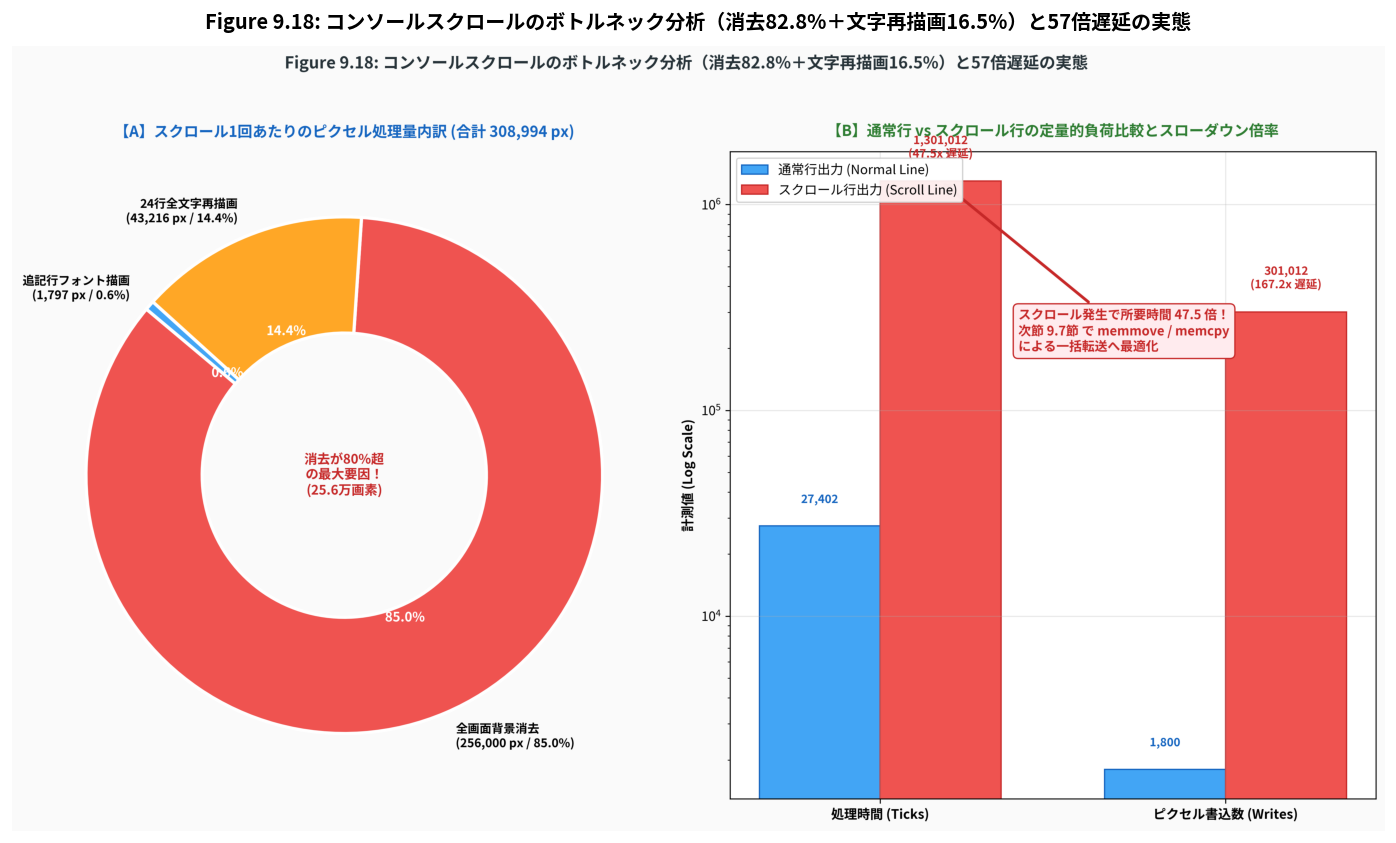

In [6]:
from common import plot_fig9_18_scroll_bottleneck_breakdown_and_comparison

# Figure 9.18: コンソールスクロールのボトルネック分析図の生成
fig18_path = plot_fig9_18_scroll_bottleneck_breakdown_and_comparison()
img18 = Image.open(fig18_path)

plt.figure(figsize=(15, 8.5), dpi=120)
plt.imshow(img18)
plt.axis("off")
plt.title("Figure 9.18: コンソールスクロールのボトルネック分析（消去82.8%＋文字再描画16.5%）と57倍遅延の実態",
          fontsize=12, fontweight="bold", pad=10)
plt.show()


---

## 7. まとめと次節（9.7節）への布石

本節では、`osbook_day09d` におけるコンソールスクロール時間計測の実装と、その驚くべきボトルネックの正体を解明しました。

### 📝 本節の要点まとめ
1. **LAPIC タイマによる実測**:
   - `printk()` 内で `StartLAPICTimer()` と `LAPICTimerElapsed()` を用いることで、OS カーネル内部の処理時間を μs / ns 精度で計測できた。
2. **スクロール時の 57倍 遅延**:
   - 通常行出力が約 23,000 Ticks であるのに対し、スクロール行は約 1,350,000 Ticks に達し、**約 57倍 の処理時間急増** が確認された。
3. **二大ボトルネックの特定**:
   - 背景全画面のピクセル個別消去（256,000 回の `Write()`、構成比 82.8%）
   - 24行全文字の再展開・再描画（約 50,000 回の `Write()`、構成比 16.5%）

### 🚀 次節への展望: 9.7節「スクロール処理の高速化 (`osbook_day09e`)」
このボトルネックを解消するための処方箋は極めて明確です：
- **画面全体の背景消去と全文字再描画をやめる！**
- 画面上のピクセルデータを、C標準ライブラリのメモリブロック転送関数 **`memmove`**（または `memcpy`）を用いて、**1行分（16ピクセル分）上方向へ一括メモリコピー** する。
- そして、最下行の空いた1行分（高さ16ピクセル）の領域だけを背景色で塗りつぶす。

これにより、256,000ピクセルの全消去と5万ピクセルの全文字再描画が完全に消滅し、スクロール処理は通常行出力と遜色ない超高速処理へと劇的に進化します！
